
Experiment 1/36
n = 10, m = 5, sigma = 0.01
Completed successfully.

Experiment 2/36
n = 10, m = 5, sigma = 0.05
Completed successfully.

Experiment 3/36
n = 10, m = 5, sigma = 0.1
Completed successfully.

Experiment 4/36
n = 10, m = 5, sigma = 0.2
Completed successfully.

Experiment 5/36
n = 10, m = 10, sigma = 0.01
Completed successfully.

Experiment 6/36
n = 10, m = 10, sigma = 0.05
Completed successfully.

Experiment 7/36
n = 10, m = 10, sigma = 0.1
Completed successfully.

Experiment 8/36
n = 10, m = 10, sigma = 0.2
Completed successfully.

Experiment 9/36
n = 10, m = 25, sigma = 0.01
Completed successfully.

Experiment 10/36
n = 10, m = 25, sigma = 0.05
Completed successfully.

Experiment 11/36
n = 10, m = 25, sigma = 0.1
Completed successfully.

Experiment 12/36
n = 10, m = 25, sigma = 0.2
Completed successfully.

Experiment 13/36
n = 20, m = 5, sigma = 0.01
Completed successfully.

Experiment 14/36
n = 20, m = 5, sigma = 0.05
Completed successfully.

Experiment 15/36
n = 20, m

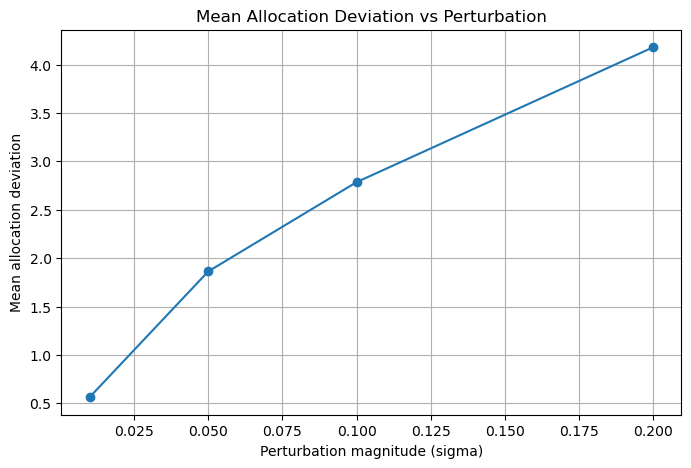

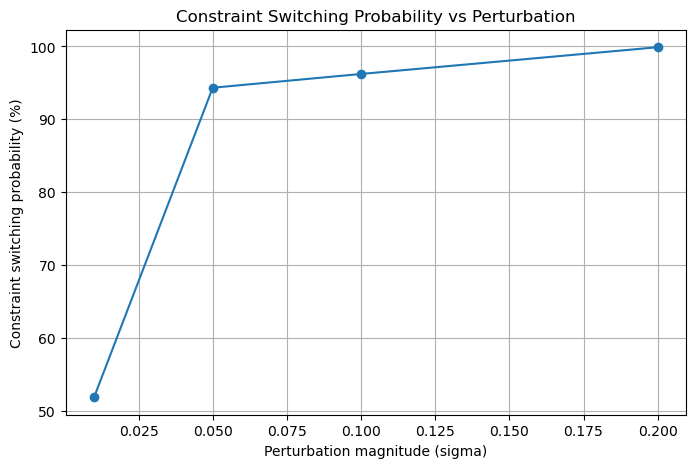

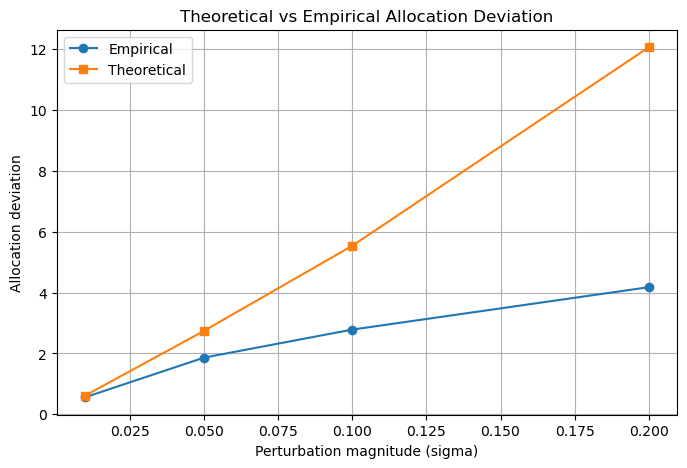



EXPERIMENT COMPLETED
Total configurations attempted: 36
Monte Carlo samples per configuration: 100
Total execution time: 12.98 seconds

The corrected program has finished.


In [3]:
# ==============================================================
# SENSITIVITY AND STABILITY ANALYSIS FOR RESOURCE ALLOCATION UNDER STOCHASTIC PERTURBATIONS
# ==============================================================

# ==============================================================
# 1. IMPORT LIBRARIES
# ==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize, LinearConstraint
import time


# ==============================================================
# 2. EXPERIMENTAL SETTINGS
# ==============================================================

N_VALUES = [10, 20, 50]

M_VALUES = [5, 10, 25]

SIGMA_VALUES = [0.01, 0.05, 0.10, 0.20]

# --------------------------------------------------------------
# IMPORTANT:
# Use 100 first to test the code.
# After confirming that it works, change to 1000.
# --------------------------------------------------------------

MONTE_CARLO_SAMPLES = 100

RANDOM_SEED = 42


# ==============================================================
# 3. GENERATE SYNTHETIC RESOURCE ALLOCATION PROBLEM
# ==============================================================

def generate_problem(n, m, seed=None):

    rng = np.random.default_rng(seed)

    # ----------------------------------------------------------
    # Generate a well-conditioned positive definite matrix Q
    # ----------------------------------------------------------

    R = rng.normal(
        0,
        1 / np.sqrt(n),
        size=(n, n)
    )

    Q = R.T @ R + np.eye(n)

    # ----------------------------------------------------------
    # Cost vector
    # ----------------------------------------------------------

    c0 = rng.uniform(
        1.0,
        5.0,
        size=n
    )

    # ----------------------------------------------------------
    # Resource constraint matrix
    # ----------------------------------------------------------

    A = rng.uniform(
        0.5,
        1.5,
        size=(m, n)
    )

    # ----------------------------------------------------------
    # Create a feasible reference allocation
    # ----------------------------------------------------------

    x_reference = rng.uniform(
        1.0,
        3.0,
        size=n
    )

    # ----------------------------------------------------------
    # Nominal demand
    # ----------------------------------------------------------

    b0 = 0.70 * (A @ x_reference)

    return Q, c0, A, b0


# ==============================================================
# 4. OBJECTIVE FUNCTION
# ==============================================================

def objective(x, Q, c):

    return (
        c @ x
        + 0.5 * x @ Q @ x
    )


# ==============================================================
# 5. OBJECTIVE GRADIENT
# ==============================================================

def objective_gradient(x, Q, c):

    return c + Q @ x


# ==============================================================
# 6. CREATE A GUARANTEED FEASIBLE STARTING POINT
# ==============================================================

def create_feasible_start(A, b):

    n = A.shape[1]

    # ----------------------------------------------------------
    # Since A contains positive values, choose x = t
    # for every variable.
    #
    # We need:
    #
    # A x >= b
    #
    # ----------------------------------------------------------

    row_sums = np.sum(A, axis=1)

    # Avoid division by zero
    row_sums = np.maximum(
        row_sums,
        1e-12
    )

    required_t = np.max(
        b / row_sums
    )

    # ----------------------------------------------------------
    # Add safety margin
    # ----------------------------------------------------------

    t = max(
        1.0,
        required_t * 1.10
    )

    x_start = np.full(
        n,
        t
    )

    # ----------------------------------------------------------
    # Numerical safety check
    # ----------------------------------------------------------

    if np.any(A @ x_start < b):

        # Increase until feasible
        for _ in range(20):

            x_start *= 1.5

            if np.all(A @ x_start >= b):

                break

    return x_start


# ==============================================================
# 7. SOLVE RESOURCE ALLOCATION PROBLEM
# ==============================================================

def solve_allocation(
    Q,
    c,
    A,
    b,
    x_start=None
):

    n = len(c)

    # ----------------------------------------------------------
    # If no starting point is provided, create a feasible one.
    # ----------------------------------------------------------

    if x_start is None:

        x_start = create_feasible_start(
            A,
            b
        )

    else:

        # ------------------------------------------------------
        # Check whether supplied starting point is feasible.
        # ------------------------------------------------------

        if np.any(A @ x_start < b):

            x_start = create_feasible_start(
                A,
                b
            )

    # ----------------------------------------------------------
    # Linear constraint:
    #
    # A x >= b
    #
    # scipy LinearConstraint format:
    #
    # lower <= A x <= upper
    #
    # Therefore:
    #
    # b <= A x <= infinity
    # ----------------------------------------------------------

    constraint = LinearConstraint(
        A,
        b,
        np.inf
    )

    # ----------------------------------------------------------
    # Non-negative allocation:
    #
    # x >= 0
    # ----------------------------------------------------------

    bounds = [
        (0, None)
        for _ in range(n)
    ]

    # ==========================================================
    # First attempt: SLSQP
    # ==========================================================

    result = minimize(
        objective,
        x_start,
        args=(Q, c),
        jac=objective_gradient,
        method="SLSQP",
        bounds=bounds,
        constraints=constraint,
        options={
            "maxiter": 2000,
            "ftol": 1e-8,
            "disp": False
        }
    )

    # ----------------------------------------------------------
    # Check solution
    # ----------------------------------------------------------

    if result.success:

        # Verify constraints
        if np.all(A @ result.x >= b - 1e-6):

            return result.x

    # ==========================================================
    # FALLBACK: trust-constr
    # ==========================================================

    result2 = minimize(
        objective,
        x_start,
        args=(Q, c),
        jac=objective_gradient,
        method="trust-constr",
        bounds=constraint_bounds(n),
        constraints=constraint,
        options={
            "maxiter": 1000,
            "verbose": 0
        }
    )

    # ----------------------------------------------------------
    # Verify fallback solution
    # ----------------------------------------------------------

    if result2.success:

        if np.all(A @ result2.x >= b - 1e-5):

            return result2.x

    # ==========================================================
    # FINAL ERROR
    # ==========================================================

    raise RuntimeError(
        "Optimization failed.\n"
        f"SLSQP message: {result.message}\n"
        f"Trust-constr message: {result2.message}"
    )


# ==============================================================
# 8. BOUND FUNCTION FOR TRUST-CONSTR
# ==============================================================

def constraint_bounds(n):

    return [
        (0, None)
        for _ in range(n)
    ]


# ==============================================================
# 9. FIND ACTIVE CONSTRAINTS
# ==============================================================

def get_active_constraints(
    x,
    A,
    b,
    tolerance=1e-5
):

    slack = A @ x - b

    active = np.where(
        np.abs(slack) <= tolerance
    )[0]

    return active, slack


# ==============================================================
# 10. CALCULATE KKT SENSITIVITY
# ==============================================================

def calculate_kkt_sensitivity(
    Q,
    A,
    active_constraints
):

    n = Q.shape[0]

    # ----------------------------------------------------------
    # Case: no active constraints
    # ----------------------------------------------------------

    if len(active_constraints) == 0:

        J_c = -np.linalg.solve(
            Q,
            np.eye(n)
        )

        J_b = np.zeros(
            (n, 0)
        )

        return J_c, J_b

    # ----------------------------------------------------------
    # Active constraint matrix
    # ----------------------------------------------------------

    A_active = A[
        active_constraints,
        :
    ]

    k = len(active_constraints)

    # ----------------------------------------------------------
    # KKT matrix
    #
    # [ Q       -A_active.T ]
    # [ A_active      0     ]
    # ----------------------------------------------------------

    KKT = np.block([
        [
            Q,
            -A_active.T
        ],
        [
            A_active,
            np.zeros((k, k))
        ]
    ])

    # ==========================================================
    # Sensitivity with respect to cost
    # ==========================================================

    RHS_c = np.vstack([
        -np.eye(n),
        np.zeros((k, n))
    ])

    try:

        solution_c = np.linalg.solve(
            KKT,
            RHS_c
        )

    except np.linalg.LinAlgError:

        solution_c = np.linalg.lstsq(
            KKT,
            RHS_c,
            rcond=None
        )[0]

    J_c = solution_c[:n, :]

    # ==========================================================
    # Sensitivity with respect to demand
    # ==========================================================

    RHS_b = np.vstack([
        np.zeros((n, k)),
        np.eye(k)
    ])

    try:

        solution_b = np.linalg.solve(
            KKT,
            RHS_b
        )

    except np.linalg.LinAlgError:

        solution_b = np.linalg.lstsq(
            KKT,
            RHS_b,
            rcond=None
        )[0]

    J_b = solution_b[:n, :]

    return J_c, J_b


# ==============================================================
# 11. RUN ONE EXPERIMENT
# ==============================================================

def run_configuration(
    n,
    m,
    sigma,
    samples,
    seed
):

    rng = np.random.default_rng(seed)

    # ----------------------------------------------------------
    # Generate nominal problem
    # ----------------------------------------------------------

    Q, c0, A, b0 = generate_problem(
        n,
        m,
        seed
    )

    # ----------------------------------------------------------
    # Solve nominal problem
    # ----------------------------------------------------------

    start_time = time.perf_counter()

    x0 = solve_allocation(
        Q,
        c0,
        A,
        b0
    )

    nominal_time = (
        time.perf_counter()
        - start_time
    )

    # ----------------------------------------------------------
    # Nominal objective
    # ----------------------------------------------------------

    f0 = objective(
        x0,
        Q,
        c0
    )

    # ----------------------------------------------------------
    # Active constraints
    # ----------------------------------------------------------

    active_constraints, nominal_slack = (
        get_active_constraints(
            x0,
            A,
            b0
        )
    )

    # ----------------------------------------------------------
    # KKT sensitivity
    # ----------------------------------------------------------

    J_c, J_b = (
        calculate_kkt_sensitivity(
            Q,
            A,
            active_constraints
        )
    )

    # ----------------------------------------------------------
    # Perturbation standard deviations
    #
    # sigma is a fraction of nominal values.
    # ----------------------------------------------------------

    sigma_c = (
        sigma
        * np.maximum(
            np.abs(c0),
            1e-8
        )
    )

    sigma_b = (
        sigma
        * np.maximum(
            np.abs(b0),
            1e-8
        )
    )

    # ==========================================================
    # Theoretical covariance
    # ==========================================================

    cov_x = (
        J_c
        @ np.diag(
            sigma_c ** 2
        )
        @ J_c.T
    )

    if len(active_constraints) > 0:

        sigma_b_active = (
            sigma_b[
                active_constraints
            ]
        )

        cov_x += (
            J_b
            @ np.diag(
                sigma_b_active ** 2
            )
            @ J_b.T
        )

    theoretical_expected_deviation = np.sqrt(
        max(
            np.trace(cov_x),
            0
        )
    )

    # ==========================================================
    # Storage
    # ==========================================================

    actual_deviations = []

    predicted_deviations = []

    objective_changes = []

    switching_count = 0

    successful_simulations = 0

    # ==========================================================
    # MONTE CARLO SIMULATION
    # ==========================================================

    simulation_start = time.perf_counter()

    for i in range(samples):

        # ------------------------------------------------------
        # Cost perturbation
        # ------------------------------------------------------

        epsilon_c = rng.normal(
            0,
            sigma_c,
            size=n
        )

        # ------------------------------------------------------
        # Demand perturbation
        # ------------------------------------------------------

        epsilon_b = rng.normal(
            0,
            sigma_b,
            size=m
        )

        # ------------------------------------------------------
        # Perturbed parameters
        # ------------------------------------------------------

        c_perturbed = (
            c0 + epsilon_c
        )

        b_perturbed = (
            b0 + epsilon_b
        )

        # ------------------------------------------------------
        # Ensure demand does not become negative
        # ------------------------------------------------------

        b_perturbed = np.maximum(
            b_perturbed,
            0
        )

        # ------------------------------------------------------
        # Solve perturbed optimization problem
        # ------------------------------------------------------

        try:

            x_perturbed = (
                solve_allocation(
                    Q,
                    c_perturbed,
                    A,
                    b_perturbed,
                    x_start=x0
                )
            )

        except RuntimeError:

            # Skip unsuccessful simulation
            continue

        successful_simulations += 1

        # ======================================================
        # Actual allocation deviation
        # ======================================================

        actual_change = np.linalg.norm(
            x_perturbed - x0
        )

        actual_deviations.append(
            actual_change
        )

        # ======================================================
        # Predicted allocation deviation
        # ======================================================

        predicted_change = (
            J_c @ epsilon_c
        )

        if len(active_constraints) > 0:

            predicted_change += (
                J_b
                @ epsilon_b[
                    active_constraints
                ]
            )

        predicted_change_norm = (
            np.linalg.norm(
                predicted_change
            )
        )

        predicted_deviations.append(
            predicted_change_norm
        )

        # ======================================================
        # Objective change
        # ======================================================

        f_perturbed = objective(
            x_perturbed,
            Q,
            c_perturbed
        )

        f_nominal_under_perturbed_cost = (
            objective(
                x0,
                Q,
                c_perturbed
            )
        )

        objective_change = abs(
            f_perturbed
            - f_nominal_under_perturbed_cost
        )

        objective_changes.append(
            objective_change
        )

        # ======================================================
        # Constraint switching
        # ======================================================

        perturbed_active, _ = (
            get_active_constraints(
                x_perturbed,
                A,
                b_perturbed
            )
        )

        if not np.array_equal(
            active_constraints,
            perturbed_active
        ):

            switching_count += 1

    simulation_time = (
        time.perf_counter()
        - simulation_start
    )

    # ==========================================================
    # CHECK WHETHER ANY SIMULATIONS SUCCEEDED
    # ==========================================================

    if successful_simulations == 0:

        raise RuntimeError(
            f"No successful simulations for "
            f"n={n}, m={m}, sigma={sigma}"
        )

    # ==========================================================
    # Convert lists to NumPy arrays
    # ==========================================================

    actual_deviations = np.array(
        actual_deviations
    )

    predicted_deviations = np.array(
        predicted_deviations
    )

    objective_changes = np.array(
        objective_changes
    )

    # ==========================================================
    # STATISTICAL METRICS
    # ==========================================================

    mean_deviation = np.mean(
        actual_deviations
    )

    std_deviation = np.std(
        actual_deviations,
        ddof=1
    )

    mean_objective_change = np.mean(
        objective_changes
    )

    switch_probability = (
        switching_count
        / successful_simulations
    )

    # ==========================================================
    # THEORY ERROR
    # ==========================================================

    if mean_deviation > 1e-12:

        theory_error = (
            abs(
                mean_deviation
                - theoretical_expected_deviation
            )
            / mean_deviation
            * 100
        )

    else:

        theory_error = np.nan

    # ==========================================================
    # RMSE
    # ==========================================================

    rmse = np.sqrt(
        np.mean(
            (
                actual_deviations
                - predicted_deviations
            ) ** 2
        )
    )

    # ==========================================================
    # MAE
    # ==========================================================

    mae = np.mean(
        np.abs(
            actual_deviations
            - predicted_deviations
        )
    )

    # ==========================================================
    # R-SQUARED
    # ==========================================================

    if (
        len(actual_deviations) > 1
        and np.std(actual_deviations) > 0
        and np.std(predicted_deviations) > 0
    ):

        correlation = np.corrcoef(
            actual_deviations,
            predicted_deviations
        )[0, 1]

        r_squared = (
            correlation ** 2
        )

    else:

        r_squared = np.nan

    # ==========================================================
    # STABILITY RATIO
    # ==========================================================

    stability_ratio = (
        mean_deviation / sigma
    )

    # ==========================================================
    # RETURN RESULTS
    # ==========================================================

    return {

        "n": n,

        "m": m,

        "sigma": sigma,

        "Mean Delta x":
            mean_deviation,

        "Std Delta x":
            std_deviation,

        "Mean Delta f":
            mean_objective_change,

        "Theory Error (%)":
            theory_error,

        "Switch Probability (%)":
            switch_probability * 100,

        "Theoretical Expected Delta x":
            theoretical_expected_deviation,

        "RMSE":
            rmse,

        "MAE":
            mae,

        "R2":
            r_squared,

        "Stability Ratio":
            stability_ratio,

        "Nominal Solve Time (sec)":
            nominal_time,

        "Monte Carlo Time (sec)":
            simulation_time,

        "Successful Simulations":
            successful_simulations,

        "Active Constraints":
            len(active_constraints)
    }


# ==============================================================
# 12. RUN ALL EXPERIMENTS
# ==============================================================

all_results = []

total_start = time.perf_counter()

total_experiments = (
    len(N_VALUES)
    * len(M_VALUES)
    * len(SIGMA_VALUES)
)

experiment_number = 0


for n in N_VALUES:

    for m in M_VALUES:

        for sigma in SIGMA_VALUES:

            experiment_number += 1

            print(
                f"\nExperiment "
                f"{experiment_number}/"
                f"{total_experiments}"
            )

            print(
                f"n = {n}, "
                f"m = {m}, "
                f"sigma = {sigma}"
            )

            try:

                result = run_configuration(
                    n=n,
                    m=m,
                    sigma=sigma,
                    samples=MONTE_CARLO_SAMPLES,
                    seed=(
                        RANDOM_SEED
                        + experiment_number
                    )
                )

                all_results.append(
                    result
                )

                print(
                    "Completed successfully."
                )

            except RuntimeError as error:

                print(
                    "Experiment skipped:"
                )

                print(error)


# ==============================================================
# 13. TOTAL EXECUTION TIME
# ==============================================================

total_time = (
    time.perf_counter()
    - total_start
)


# ==============================================================
# 14. CREATE RESULTS DATAFRAME
# ==============================================================

results_df = pd.DataFrame(
    all_results
)


print("\n")
print("=" * 80)
print("DETAILED EXPERIMENTAL RESULTS")
print("=" * 80)

if len(results_df) > 0:

    print(
        results_df.to_string(
            index=False
        )
    )

else:

    print(
        "No experiments completed."
    )


# ==============================================================
# 15. AGGREGATED RESULTS
# ==============================================================

if len(results_df) > 0:

    summary = (
        results_df
        .groupby("sigma")
        .agg({

            "Mean Delta x": "mean",

            "Std Delta x": "mean",

            "Mean Delta f": "mean",

            "Theory Error (%)": "mean",

            "Switch Probability (%)": "mean",

            "Theoretical Expected Delta x": "mean",

            "RMSE": "mean",

            "MAE": "mean",

            "R2": "mean",

            "Stability Ratio": "mean"

        })
        .reset_index()
    )

    print("\n")
    print("=" * 80)
    print("AGGREGATED RESULTS")
    print("=" * 80)

    print(
        summary.to_string(
            index=False
        )
    )


# ==============================================================
# 16. SAVE RESULTS
# ==============================================================

if len(results_df) > 0:

    results_df.to_csv(
        "old_paper_detailed_results.csv",
        index=False
    )

    summary.to_csv(
        "old_paper_stability_results.csv",
        index=False
    )

    print("\n")
    print(
        "Results saved successfully:"
    )

    print(
        "old_paper_detailed_results.csv"
    )

    print(
        "old_paper_stability_results.csv"
    )


# ==============================================================
# 17. PLOT — MEAN ALLOCATION DEVIATION
# ==============================================================

if len(results_df) > 0:

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        summary["sigma"],
        summary["Mean Delta x"],
        marker="o"
    )

    plt.xlabel(
        "Perturbation magnitude (sigma)"
    )

    plt.ylabel(
        "Mean allocation deviation"
    )

    plt.title(
        "Mean Allocation Deviation vs Perturbation"
    )

    plt.grid(True)

    plt.show()


# ==============================================================
# 18. PLOT — CONSTRAINT SWITCHING
# ==============================================================

if len(results_df) > 0:

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        summary["sigma"],
        summary["Switch Probability (%)"],
        marker="o"
    )

    plt.xlabel(
        "Perturbation magnitude (sigma)"
    )

    plt.ylabel(
        "Constraint switching probability (%)"
    )

    plt.title(
        "Constraint Switching Probability vs Perturbation"
    )

    plt.grid(True)

    plt.show()


# ==============================================================
# 19. PLOT — THEORY VS EMPIRICAL
# ==============================================================

if len(results_df) > 0:

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        summary["sigma"],
        summary["Mean Delta x"],
        marker="o",
        label="Empirical"
    )

    plt.plot(
        summary["sigma"],
        summary["Theoretical Expected Delta x"],
        marker="s",
        label="Theoretical"
    )

    plt.xlabel(
        "Perturbation magnitude (sigma)"
    )

    plt.ylabel(
        "Allocation deviation"
    )

    plt.title(
        "Theoretical vs Empirical Allocation Deviation"
    )

    plt.legend()

    plt.grid(True)

    plt.show()


# ==============================================================
# 20. FINAL MESSAGE
# ==============================================================

print("\n")
print("=" * 80)
print("EXPERIMENT COMPLETED")
print("=" * 80)

print(
    f"Total configurations attempted: "
    f"{total_experiments}"
)

print(
    f"Monte Carlo samples per configuration: "
    f"{MONTE_CARLO_SAMPLES}"
)

print(
    f"Total execution time: "
    f"{total_time:.2f} seconds"
)

print(
    "\nThe corrected program has finished."
)